In [56]:
import os
import yaml
import pandas as pd
import matplotlib.pyplot as plt
import cv2

dataset_dir = "Helmet and Vest.v1i.yolov8"

with open(f"{dataset_dir}/data.yaml", "r") as f:
    data_cfg = yaml.safe_load(f)
classes = data_cfg["names"]
print("Sınıflar:", classes)

splits = ["train", "valid", "test"]
split_counts = {}

for s in splits:
    img_folder = os.path.join(dataset_dir, s, "images")
    if os.path.exists(img_folder):
        split_counts[s] = len(os.listdir(img_folder))

df_splits = pd.DataFrame(list(split_counts.items()), columns=["Bölüm", "Görsel Sayısı"])
df_splits["Yüzde (%)"] = (df_splits["Görsel Sayısı"] / df_splits["Görsel Sayısı"].sum() * 100).round(1)
display(df_splits)

Sınıflar: ['helmet', 'vest']


,Bölüm,Görsel Sayısı,Yüzde (%)
0,train,147,87.5
1,valid,14,8.3
2,test,7,4.2


In [57]:
import os
import pathlib
import pandas as pd
from test_erisim import model   # __main__ qoruması olduğu üçün təhlükəsizdir

dataset_dir = "Helmet and Vest.v1i.yolov8"
test_img = os.path.join(dataset_dir, "test", "images")
test_lbl = os.path.join(dataset_dir, "test", "labels")
extra_dir = "test_cases"          # both/ helmet_only/ vest_only/ none/ alt qovluqları
THRESHOLDS = [0.3, 0.4, 0.5, 0.6, 0.7]
EXTS = (".png", ".jpg", ".jpeg")

def qrup_ve_gozlenen(h, v):
    grup = "both" if h and v else "helmet_only" if h else "vest_only" if v else "none"
    return grup, ("APPROVED" if h and v else "DENIED")

# ---- nümunələri topla: (yol, mənbə, qrup, gözlənilən) ----
samples = []

for f in os.listdir(test_img):
    if f.lower().endswith(EXTS):
        lbl = os.path.join(test_lbl, os.path.splitext(f)[0] + ".txt")
        found = set()
        if os.path.exists(lbl):
            with open(lbl) as fh:
                found = {model.names[int(float(l.split()[0]))] for l in fh if l.strip()}
        grup, exp = qrup_ve_gozlenen("helmet" in found, "vest" in found)
        samples.append((os.path.join(test_img, f), "dataset", grup, exp))

if os.path.isdir(extra_dir):
    for grup in ["both", "helmet_only", "vest_only", "none"]:
        exp = "APPROVED" if grup == "both" else "DENIED"
        for p in pathlib.Path(extra_dir, grup).glob("*.*"):
            if p.suffix.lower() in EXTS:
                samples.append((str(p), "oz_sekiller", grup, exp))

# ---- hər şəkil üçün modeli BİR dəfə işlət (aşağı conf ilə), sonra hədləri süz ----
raw = {}
for path, *_ in samples:
    r = model.predict(source=path, conf=0.1, imgsz=640, device="cpu",
                      workers=0, verbose=False)[0]
    raw[path] = [(model.names[int(b.cls[0])], float(b.conf[0])) for b in r.boxes]

def karar(path, thr):
    found = {n for n, c in raw[path] if c >= thr}
    return "APPROVED" if ("helmet" in found and "vest" in found) else "DENIED"

# ---- nəticələr ----
rows = []
for thr in THRESHOLDS:
    for path, src, grup, exp in samples:
        pred = karar(path, thr)
        rows.append({"thr": thr, "file": os.path.basename(path), "source": src,
                     "group": grup, "expected": exp, "predicted": pred,
                     "correct": pred == exp})
df = pd.DataFrame(rows)

print("=== Qrup sayları ===")
print(pd.DataFrame(samples, columns=["path", "source", "group", "exp"])
        .groupby(["source", "group"]).size())

print("\n=== Hədd üzrə ümumi nəticə ===")
summary = df.groupby("thr").apply(lambda g: pd.Series({
    "dəqiqlik": g["correct"].mean().round(3),
    "false_approve": ((g.expected == "DENIED") & (g.predicted == "APPROVED")).sum(),
    "false_deny": ((g.expected == "APPROVED") & (g.predicted == "DENIED")).sum(),
}))
print(summary)

print("\n=== conf=0.5: qrup üzrə dəqiqlik ===")
d05 = df[df.thr == 0.5]
print(d05.groupby(["source", "group"])["correct"].agg(["mean", "count"]).round(3))
print("\n", pd.crosstab(d05["expected"], d05["predicted"]))

d05[~d05["correct"]].to_csv("errors.csv", index=False)
print("\nSəhvlər errors.csv faylına yazıldı.")

=== Qrup sayları ===
source   group
dataset  both     7
dtype: int64

=== Hədd üzrə ümumi nəticə ===
     dəqiqlik  false_approve  false_deny
thr                                     
0.3       1.0            0.0         0.0
0.4       1.0            0.0         0.0
0.5       1.0            0.0         0.0
0.6       1.0            0.0         0.0
0.7       1.0            0.0         0.0

=== conf=0.5: qrup üzrə dəqiqlik ===
               mean  count
source  group             
dataset both    1.0      7

 predicted  APPROVED
expected           
APPROVED          7

Səhvlər errors.csv faylına yazıldı.


Boş etiket dosyası sayısı (nesnesiz görseller): 0
Sınıf etiket sayıları: {'helmet': 283, 'vest': 272}


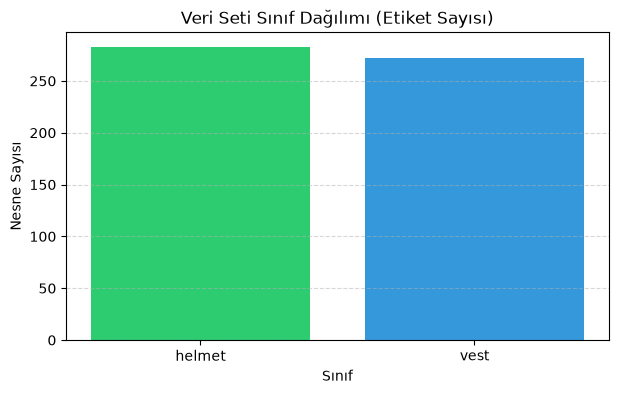

In [58]:
from collections import Counter

class_counts = Counter()
empty_labels = 0

for s in splits:
    lbl_folder = os.path.join(dataset_dir, s, "labels")
    if not os.path.exists(lbl_folder):
        continue
    for lbl_file in os.listdir(lbl_folder):
        path = os.path.join(lbl_folder, lbl_file)
        with open(path, "r") as f:
            lines = f.readlines()
            if not lines:
                empty_labels += 1
            for line in lines:
                cls_id = int(float(line.split()[0]))
                class_counts[classes[cls_id]] += 1

print("Boş etiket dosyası sayısı (nesnesiz görseller):", empty_labels)
print("Sınıf etiket sayıları:", dict(class_counts))

plt.figure(figsize=(7, 4))
plt.bar(class_counts.keys(), class_counts.values(), color=["#2ecc71", "#3498db"])
plt.title("Veri Seti Sınıf Dağılımı (Etiket Sayısı)")
plt.xlabel("Sınıf")
plt.ylabel("Nesne Sayısı")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

In [59]:
sizes = set()
img_folder = os.path.join(dataset_dir, "train", "images")

for img_name in os.listdir(img_folder):
    img = cv2.imread(os.path.join(img_folder, img_name))
    if img is not None:
        sizes.add((img.shape[1], img.shape[0]))  # (Genişlik, Yükseklik)

print("Train görsellerinin çözünürlükleri (Genişlik x Yükseklik):", sizes)

Train görsellerinin çözünürlükleri (Genişlik x Yükseklik): {(640, 640)}


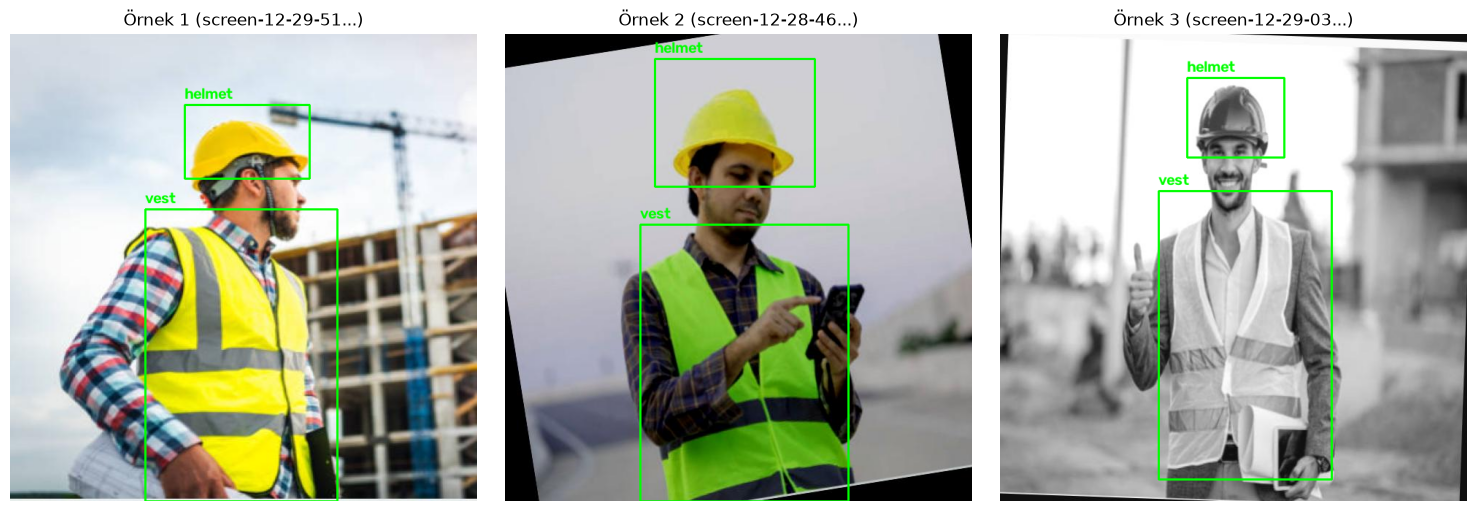

In [60]:
import os
import random
import cv2
import matplotlib.pyplot as plt

img_dir = os.path.join(dataset_dir, "train", "images")
lbl_dir = os.path.join(dataset_dir, "train", "labels")


all_images = [f for f in os.listdir(img_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]


random.shuffle(all_images)

selected_imgs = []
seen_prefixes = set()


for img_name in all_images:
    
    base_name = img_name.split('_')[0].split('.')[0][:8] 
    if base_name not in seen_prefixes:
        seen_prefixes.add(base_name)
        selected_imgs.append(img_name)
    if len(selected_imgs) == 3:
        break


if len(selected_imgs) < 3:
    selected_imgs = random.sample(all_images, 3)

plt.figure(figsize=(15, 5))
for i, img_name in enumerate(selected_imgs):
    img_path = os.path.join(img_dir, img_name)
    lbl_path = os.path.join(lbl_dir, os.path.splitext(img_name)[0] + ".txt")
    
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape
    
    if os.path.exists(lbl_path):
        with open(lbl_path, "r") as f:
            for line in f:
                parts = line.strip().split()
                if not parts:
                    continue
                cls_id = int(parts[0])
                xc, yc, bw, bh = map(float, parts[1:5])
                
                x1 = int((xc - bw / 2) * w)
                y1 = int((yc - bh / 2) * h)
                x2 = int((xc + bw / 2) * w)
                y2 = int((yc + bh / 2) * h)
                
                label_name = classes[cls_id]
                cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
                cv2.putText(img, label_name, (x1, max(y1 - 8, 15)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
    
    plt.subplot(1, 3, i + 1)
    plt.imshow(img)
    plt.title(f"Örnek {i+1} ({img_name[:15]}...)")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [61]:
from ultralytics import YOLO


model = YOLO("yolov8n.pt")


sonuclar = model.train(
    data="Helmet and Vest.v1i.yolov8/data.yaml",
    epochs=25,
    imgsz=640,
    batch=16,
    name="ppe_yolov8n_baseline"
)

Ultralytics 8.4.218  Python-3.11.1 torch-2.15.0+cpu CPU (Intel Core 5 210H)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=Helmet and Vest.v1i.yolov8/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ppe_yolov8n_baseline-8, nbs=64, nms=None, opset=None, optimi